# 2.3.- Intervalos de Confianza y Escalado de Variables

Vamos a generar un conjunto de datos artificial siguiendo la ecuación:

$$ y = 2x + 5 + \varepsilon $$

donde:
- $\varepsilon \sim N(0, 3)$ es un término de ruido gaus
- siano.  
- Esto simula un escenario real: la relación entre $x$ e $y$ es lineal, pero con cierta variabilidad aleatoria.

In [3]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [4]:
# Semilla para reproducibilidad
np.random.seed(33)

# Generamos datos lineales con ruido gaussiano
x = np.linspace(0, 10, 50)
y = 2 * x + 5 + np.random.normal(0, 3, size=len(x))

# Guardamos en un DataFrame
df = pd.DataFrame({"x": x, "y": y})
df.sample(5)  # muestra aleatoria de los datos

,x,y
49,10.000000,29.463009
17,3.469388,14.437695
23,4.693878,15.391156
19,3.877551,13.785490
20,4.081633,17.801356


## Ajuste del modelo OLS e intervalos de confianza

Usamos `statsmodels.OLS` para estimar los coeficientes de la regresión lineal:

$$ \hat{y} = \beta_0 + \beta_1 x $$

El resumen del modelo incluye:

- Los valores estimados de $\beta_0$ (intercepto) y $\beta_1$ (pendiente).
- Sus errores estándar.
- Los **intervalos de confianza (IC)** al 95% para cada coeficiente.

In [5]:
# Añadimos la constante (columna de 1s para el intercepto)
X = sm.add_constant(df["x"])

# Ajustamos el modelo OLS
model = sm.OLS(df["y"], X).fit()

# Resumen del modelo con IC de los coeficientes
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.822
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     221.4
Date:                Fri, 09 Oct 2026   Prob (F-statistic):           1.32e-19
Time:                        12:10:15   Log-Likelihood:                -123.29
No. Observations:                  50   AIC:                             250.6
Df Residuals:                      48   BIC:                             254.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.0097      0.810      4.949      0.000       2.381       5.639
x              2.0774      0.140     14.880      0.000       1.797       2.358
==============================================================================
Omnibus:                        0.871   Durbin-Watson:                   1.952
Prob(Omnibus):                  0.647   Jarque-Bera (JB):                0.897
Skew:                           0.290   Prob(JB):                        0.639
Kurtosis:                       2.695   Cond. No.                         11.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Visualización de la recta de regresión con intervalo de confianza (95%)

Podemos representar gráficamente:

- Los **puntos observados** (x, y).  
- La **recta ajustada** con OLS.  
- La **banda de confianza al 95%**, que muestra la incertidumbre del ajuste.

La banda se interpreta así:  
- Si repitiéramos el muestreo muchas veces, el 95% de las rectas ajustadas estarían dentro de esa franja.  
- Ojo: el IC no significa que el 95% de los datos estén dentro de la franja.

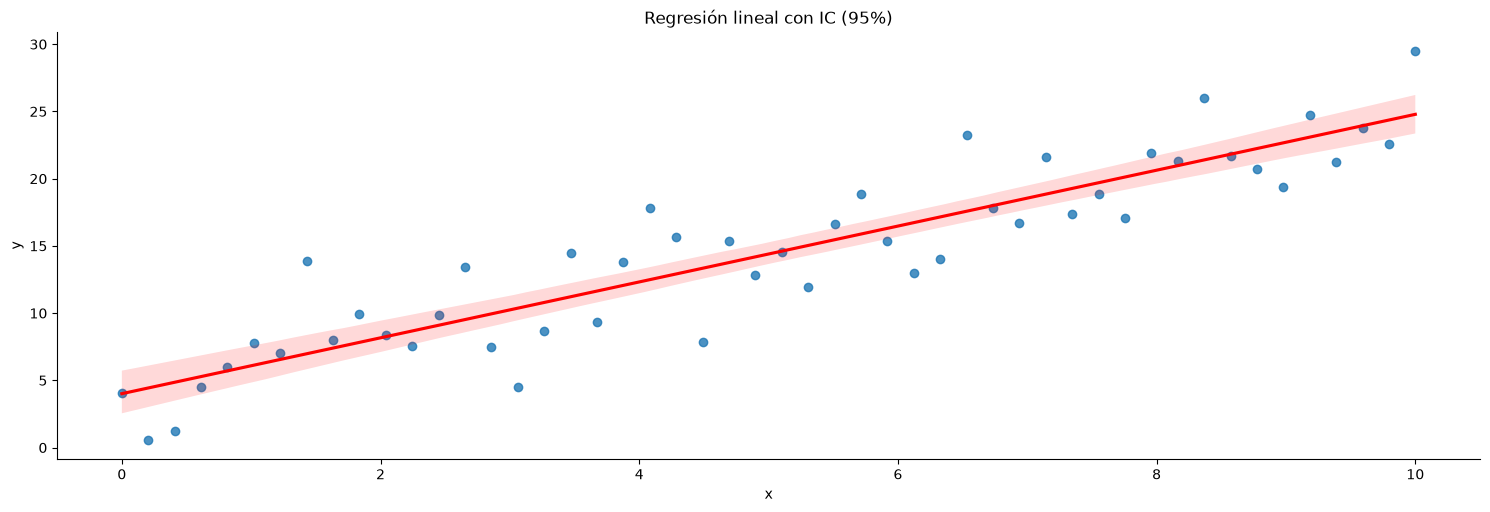

In [6]:
# Gráfico de la regresión con banda de IC al 95%
sns.lmplot(x="x", y="y", data=df, ci=95, line_kws={"color": "red"}, height=5, aspect=3)
plt.title("Regresión lineal con IC (95%)")
plt.show()

## Escalado de variables con StandardScaler

En regresión y en otros algoritmos de Machine Learning es común **escalar las variables**.  

Motivación:
- Si las variables tienen órdenes de magnitud muy diferentes (ej. `metros` frente a `euros`),  
  los coeficientes pueden quedar desbalanceados.  
- En métodos iterativos como el **descenso del gradiente**, el escalado acelera y estabiliza la convergencia.  

El **StandardScaler** transforma cada variable de forma que tenga:
- **Media = 0**  
- **Desviación estándar = 1**

Esto facilita la comparación y el entrenamiento de los modelos.

In [7]:
# Inicializamos el escalador
scaler = StandardScaler()

# Ajustamos y transformamos la variable x
X_scaled = scaler.fit_transform(df[["x"]])

# Comprobamos media y desviación estándar
print("Media escalada:", X_scaled.mean())
print("Desviación estándar:", X_scaled.std())

# Creamos un DataFrame con los valores originales y escalados
df_scaled = df.copy()
df_scaled["x_escalada"] = X_scaled

# Mostramos comparación
df_scaled.head(10)

Media escalada: 4.884981308350689e-17
Desviación estándar: 1.0


,x,y,x_escalada
0,0.000000,4.043439,-1.697749
1,0.204082,0.599222,-1.628453
2,0.408163,1.210673,-1.559158
3,0.612245,4.513287,-1.489862
4,0.816327,5.982468,-1.420566
5,1.020408,7.805439,-1.351270
6,1.224490,7.000630,-1.281974
7,1.428571,13.889491,-1.212678
8,1.632653,7.974954,-1.143382
9,1.836735,9.940074,-1.074086
